# Case Study 29 — Did the Nudge Cut Penny-Stock Trading, or Did the Market? Pre/Post vs Interrupted Time Series vs Difference-in-Differences vs a Holdout

**Priority:** ★★ Good to have · **Reference:** Case Study 29 — *Zerodha: nudging first-time investors away from penny stocks* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Product heads (trading platform), Compliance / investor protection, Leadership
**Data:** ⚠️ **SYNTHETIC** (D-29-01). Broker trade data are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs29_penny_stock_nudge_causal.ipynb`

## 0. Executive Summary for Business

*(Synthetic data built on Zerodha's documented intervention and "more than 50%" headline. The true effect is set at −30% so that methods can be judged against it. Written after the analysis.)*

- **The question:** did the point-of-trade warning really halve penny-stock trading by first-time investors, or did a cooling market do part of the work?
- **The four methods give very different answers:**

| Method | Estimate | Verdict |
|---|---|---|
| Before vs after (as reported) | **−62.5%** | Wrong: other brokers, with no nudge, fell **−46.8%** over the same windows. Most of the "drop" is the market fading after the 2020 boom. |
| Interrupted time series, own trend only | −72% | Worse, because it extends the boom-era trend |
| Interrupted time series + market control | −20% (CI −30% to −8%) | Closer |
| **Difference-in-differences vs other brokers**, using the staggered web → Android → iOS rollout | **−28.3%** (CI −30.0% to −26.5%) | Close to the truth |
| **Randomised 5% holdout** of users never nudged | **−31.9%** (CI −35% to −29%) | Close to the truth (−30%) |

- **The checks that make the DiD credible:**
  - Placebo launch dates find ≈ 0 in 8 of 9 cases.
  - The event study is flat before each launch (wobbles ≤ 6%) and drops after.
  - Allowing each platform its own trend still gives −25% to −27%.
- **The nudge works,** cutting penny trading by about **30%**, which is very valuable. But the headline "more than 50%" overstates it roughly 2×.
- **₹ impact (a broker with 20 lakh active first-time investors):** the holdout implies ≈ **₹220 crore/year of investor losses avoided** (₹280 per user per quarter). Pre/post would have claimed ≈ ₹430 crore. "Tens of crores" is, if anything, conservative.
- **I recommend:**
  - Keep the nudge.
  - Report its impact with a control (staggered rollout + other-broker benchmark) or a small permanent holdout (2–5% detects a 7–10% change).
  - Never use a pre/post comparison through a market turn.

## 1. The Problem in Simple English

Zerodha shows first-time investors a warning ("Nudge") when they try to buy penny stocks or illiquid instruments, which carry a high risk of loss. Afterwards, penny-stock trading on its platform fell by **more than 50%**. That is a good outcome, but was it the nudge?

The nudge launched while the market itself was changing. In 2020–21, a speculative boom in small and penny stocks peaked and then faded. If penny trading was falling **everywhere**, a before/after comparison on one platform credits the nudge with the market's cooling.

This notebook applies four increasingly credible methods to the same question:
1. **Before/after** (what was reported).
2. **Interrupted time series**: does the trend break at launch?
3. **Difference-in-differences**: compare with other brokers who had no nudge, and use the staggered rollout across web, Android and iOS.
4. **A randomised holdout** of users who never see the nudge: the gold standard Zerodha could add.

## 2. Reference from the Case File

### (a) What Zerodha did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "First-time investors were trading penny stocks and illiquid instruments, with a high risk of losses" |
| Question | "Can contextual warnings at the point of trade reduce risky trading?" |
| Data | Trade attempts (instrument type, liquidity, user profile, rules-based); Zerodha "deliberately does not run behavioural tracking or engagement analytics" |
| Approach | "Rules flag risky instruments, and a 'Nudge' warning appears when a trade is attempted" |
| Statistics | "Before/after comparison of penny-stock volumes. **No control group is stated.**" |
| ML | **None** (rule-based) |
| Impact | "Penny stock trading volumes on Kite have dropped by **more than 50%**, probably saving tens of crores of rupees." The reference file notes this is before/after only; causality is not established |

**Sources:** Zerodha Z-Connect (Nithin Kamath), 15 Aug 2020; Kailash Nadh, "User disengagement", 6 May 2022 (links in the reference file).

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | ≈ 18 months of daily penny-stock trades by first-time investors on 3 platforms (web, Android, iOS), plus **other brokers** with no nudge (control). A **market boom-and-fade** in speculative penny interest affects everyone. The nudge rolls out **staggered**: web (day 230), Android (262), iOS (300). **True effect: −30%.** Plus 120,000 users over 90 days with a **5% randomised holdout** that never sees nudges. |
| Statistics added | Pre/post rate ratio; **interrupted time series** (segmented regression, Newey–West SEs) with and without a market control; **difference-in-differences** (log counts, platform and date fixed effects); **event study** with pre-trend tests; **placebo launch dates**; holdout ITT with CIs; power; ₹ losses avoided under each estimate |

### (c) How the industry uses this

Every product team in Indian fintech launches features into moving markets: brokers (nudges, F&O risk warnings mandated by SEBI in 2023–24), lenders (new collection scripts), payment apps (UPI Lite, autopay prompts). **Pre/post claims are the most common, and most commonly overstated, impact numbers in press releases.** Staggered rollouts, never-treated comparison groups and small permanent holdouts are the standard ways to measure such launches credibly.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | How much did the nudge reduce risky penny-stock trading by first-time investors, and how much money did it save them? |
| Analytical | What is the causal % change in penny trades attributable to the nudge, net of market-wide changes? |

**Hypotheses**
- **H1 (pre/post):** H0: daily penny trades are the same before and after (Poisson rate ratio). This is what was reported.
- **H2 (ITS):** H0: no level/trend break at launch, controlling for the market (segmented regression).
- **H3 (DiD):** H0: the platform-vs-control gap does not change when the nudge goes live (log-linear two-way fixed effects; event-study leads test the parallel-trends assumption).
- **H4 (holdout):** H0: users in the no-nudge holdout trade penny stocks as often as nudged users (two-proportion z).

**Primary estimate:** the holdout ITT where available; otherwise DiD. **Estimand:** % change in penny trades by first-time investors.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint, confint_proportions_2indep, proportions_ztest

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Broker-level penny trades by first-time investors | **None public.** Zerodha shared only the headline. Exchanges (NSE/BSE) publish aggregate volumes by security, not by broker or investor experience. |
| **Decision** | Synthetic daily series with a market cycle, a control group and a staggered rollout; synthetic user holdout (D-29-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs29.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 29 (Zerodha-style point-of-trade "Nudge" against penny-stock trading)
==========================================================================================================
THIS DATA IS SYNTHETIC. Broker trade data are confidential.

Daily penny-stock trades by FIRST-TIME investors on a broker's three platforms (web, Android, iOS) over
~18 months, plus the same series for a group of OTHER BROKERS that never introduced a nudge (control).
Market-wide speculative interest in penny stocks rises sharply (a small-cap boom), peaks, then fades -
so a simple before/after comparison around the nudge launch mixes the nudge with the market cycle.
The nudge (a warning when a risky trade is attempted) rolls out in a STAGGERED way: web first, then
Android, then iOS. The TRUE effect is a ~30% reduction in penny trades on a platform once its nudge is live.
A user-level dataset adds what a careful team would also run: a 5% randomised HOLDOUT that never sees nudges.

Calibration anchors (reference file, Case Study 29): "Penny stock trading volumes on Kite have dropped by
more than 50%"; before/after only, "No control group is stated"; nudges at the point of trade; no ML.
Rates are our assumptions (decision.md D-29-02). Hidden truth columns start with "_".

Outputs: data/cs29/daily_trades.csv.gz, data/cs29/user_holdout.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
START = pd.Timestamp("2020-01-01"); DAYS = 540
LAUNCH = {"web": 230, "android": 262, "ios": 300}          # nudge go-live day index per platform (staggered)
TRUE_EFFECT = 0.30


def market_index(d):
    """Speculative penny-stock interest: boom to a peak around day 200, then a fade (the confounder)."""
    return 1.0 + 1.8 * np.exp(-((d - 200) / 70.0) ** 2) + 0.25 * (d / DAYS)


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    d = np.arange(DAYS); dates = START + pd.to_timedelta(d, unit="D"); wd = dates.weekday.values; trading = wd < 5
    M = market_index(d) * np.exp(rng.normal(0, 0.04, DAYS))
    rows = []
    base = {"web": 1800, "android": 2600, "ios": 900, "other_brokers": 9000}
    beta = {"web": 1.0, "android": 1.0, "ios": 1.0, "other_brokers": 1.0}
    growth = {"web": 0.0006, "android": 0.0012, "ios": 0.0010, "other_brokers": 0.0009}       # customer-base growth
    for p, b0 in base.items():
        post = (d >= LAUNCH[p]) if p in LAUNCH else np.zeros(DAYS, bool)
        ramp = np.clip((d - LAUNCH.get(p, 10 ** 6)) / 10, 0, 1)                                  # effect builds over 10 days
        lam = b0 * M ** beta[p] * np.exp(growth[p] * d) * (1 - TRUE_EFFECT * ramp) * np.exp(rng.normal(0, 0.06, DAYS))
        trades = np.where(trading, rng.poisson(lam), 0)
        rows.append(pd.DataFrame({"date": dates, "platform": p, "penny_trades_first_time": trades, "active_first_time_investors": np.where(trading, np.round(lam / 0.12 * rng.uniform(0.97, 1.03, DAYS)), 0),
                                  "nudge_live": post.astype(int), "_market_index": M}))
    daily = pd.concat(rows, ignore_index=True)
    daily = daily[daily.date.dt.weekday < 5].reset_index(drop=True)
    # user-level holdout over the 90 days after full rollout (day 300-390)
    n = 120_000; hold = (rng.random(n) < 0.05).astype(int)
    spec = rng.normal(0, 1, n); age = np.clip(rng.normal(27, 6, n), 18, 65).round(); capital = np.exp(rng.normal(np.log(15000), 0.9, n))
    p_trade = expit(-1.4 + 0.9 * spec - 0.02 * (age - 27) - 0.1 * np.log(capital / 15000)) * np.where(hold == 1, 1.0, 1 - TRUE_EFFECT)
    traded = (rng.random(n) < p_trade).astype(int)
    loss = np.where(traded == 1, np.round(np.exp(rng.normal(np.log(2200), 1.0, n)), 0), 0)
    users = pd.DataFrame({"user_id": [f"Z{i:06d}" for i in range(n)], "holdout_no_nudge": hold, "age": age, "starting_capital_inr": np.round(capital, -2),
                          "traded_penny_90d": traded, "penny_loss_90d_inr": loss, "_spec": spec})
    # data-quality defects
    daily.loc[daily.sample(n=6, random_state=seed).index, "penny_trades_first_time"] = 0                      # exchange file not received -> zero
    daily = pd.concat([daily, daily.sample(n=20, random_state=seed + 1)], ignore_index=True)
    return daily, users


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs29"), exist_ok=True)
    dly, us = generate(); dly.to_csv(os.path.join(here, "cs29", "daily_trades.csv.gz"), index=False); us.to_csv(os.path.join(here, "cs29", "user_holdout.csv.gz"), index=False)
    z = dly[dly.platform != "other_brokers"].groupby("date").penny_trades_first_time.sum()
    pre = z[(z.index >= START + pd.Timedelta(days=170)) & (z.index < START + pd.Timedelta(days=230))].mean(); post = z[(z.index >= START + pd.Timedelta(days=330)) & (z.index < START + pd.Timedelta(days=390))].mean()
    print("broker pre (60d before web launch) vs post (60d after full rollout+30):", round(pre), round(post), "change", round(post / pre - 1, 3))
    print(us.groupby("holdout_no_nudge").traded_penny_90d.mean().round(4).to_dict())

Overwriting data/generate_cs29.py


In [3]:
os.makedirs("data/cs29", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs29 as gen; importlib.reload(gen)
daily_raw, users = gen.generate(seed=SEED)
daily_raw.to_csv("data/cs29/daily_trades.csv.gz", index=False); users.to_csv("data/cs29/user_holdout.csv.gz", index=False)
print(f"{len(daily_raw):,} platform-day rows | {users.shape[0]:,} users in the holdout study")
daily_raw.drop(columns=["_market_index"]).head(4)

1,564 platform-day rows | 120,000 users in the holdout study


,date,platform,penny_trades_first_time,active_first_time_investors,nudge_live
0,2020-01-01,web,1572,"13,373.0000",0
1,2020-01-02,web,1683,"14,013.0000",0
2,2020-01-03,web,1948,"16,048.0000",0
3,2020-01-06,web,1709,"13,812.0000",0


| Parameter | Value | Basis |
|---|---|---|
| Period | 1 Jan 2020 → mid-2021, trading days only | Covers the documented Aug 2020 period and the 2020–21 small-cap boom |
| Market confounder | Speculative penny interest rises ~2.8× to a peak (~day 200), then fades | Stylised boom-and-fade; affects all brokers |
| Rollout | Nudge live on web day 230, Android day 262, iOS day 300 (effect builds over ~10 days) | Our assumption: staggered roll-outs are typical |
| True effect | −30% penny trades on a platform once its nudge is live | Our assumption (below the documented "> 50%") |
| Control | Other brokers' first-time investors: same market, no nudge | Our design |
| Holdout | 120,000 users × 90 days after full rollout; 5% never nudged | Our design (what a careful team adds) |
| DQ issues | 20 duplicated platform-days; 6 days where the exchange file did not arrive (zeros) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("daily_trades: date, platform", "Trading day; web / android / ios / other_brokers"), ("penny_trades_first_time", "Penny-stock trades by first-time investors that day"),
    ("active_first_time_investors", "Active first-time investors that day (exposure)"), ("nudge_live", "1 once that platform's nudge is live"),
    ("_market_index", "HIDDEN market-wide speculative interest"), ("user_holdout: holdout_no_nudge", "1 = randomised 5% who never see nudges"),
    ("traded_penny_90d, penny_loss_90d_inr", "Any penny trade in 90 days; realised loss"), ("_spec", "HIDDEN speculative propensity"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs29/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"daily_trades: date, platform",Trading day; web / android / ios / other_brokers
1,penny_trades_first_time,Penny-stock trades by first-time investors tha...
2,active_first_time_investors,Active first-time investors that day (exposure)
3,nudge_live,1 once that platform's nudge is live
4,_market_index,HIDDEN market-wide speculative interest
5,user_holdout: holdout_no_nudge,1 = randomised 5% who never see nudges
6,"traded_penny_90d, penny_loss_90d_inr",Any penny trade in 90 days; realised loss
7,_spec,HIDDEN speculative propensity


## 5. Data Quality Checks

In [5]:
dup = daily_raw.duplicated(["date", "platform"]).sum()
d0 = daily_raw.drop_duplicates(["date", "platform"]).copy()
zero = d0[(d0.penny_trades_first_time == 0)]
print(pd.Series({"duplicated platform-day rows": int(dup), "zero-trade platform-days (missing exchange files)": len(zero)}, name="rows").to_string())
print("Zero days:", sorted(zip(zero.date.dt.date.astype(str), zero.platform)))
d0.loc[d0.penny_trades_first_time == 0, "penny_trades_first_time"] = np.nan
d0["t"] = (d0.date - gen.START).dt.days; d0["ly"] = np.log(d0.penny_trades_first_time); d0["week"] = d0.t // 7
W = d0.pivot(index="date", columns="platform", values="penny_trades_first_time")
broker = W[["web", "android", "ios"]].sum(1, min_count=3)
print(f"\nClean: {d0.date.nunique()} trading days × 4 series | missing days set to NaN (never as zero trades)")

duplicated platform-day rows                         20
zero-trade platform-days (missing exchange files)     6
Zero days: [('2020-02-19', 'ios'), ('2020-06-03', 'other_brokers'), ('2020-07-17', 'android'), ('2020-08-07', 'android'), ('2021-03-26', 'ios'), ('2021-04-15', 'other_brokers')]

Clean: 386 trading days × 4 series | missing days set to NaN (never as zero trades)


**Observation:** we removed **20 duplicated platform-days** and found **6 trading days with zero trades** on one series while the others were normal: the exchange file had not arrived. They are set to **missing, not zero**. Treating them as zero would create fake "drops" on those days, and on a log scale they cannot be analysed at all. Clean: **386 trading days × 4 series** (web, Android, iOS, other brokers), plus 120,000 users in the holdout study.

## 6. Exploratory Data Analysis

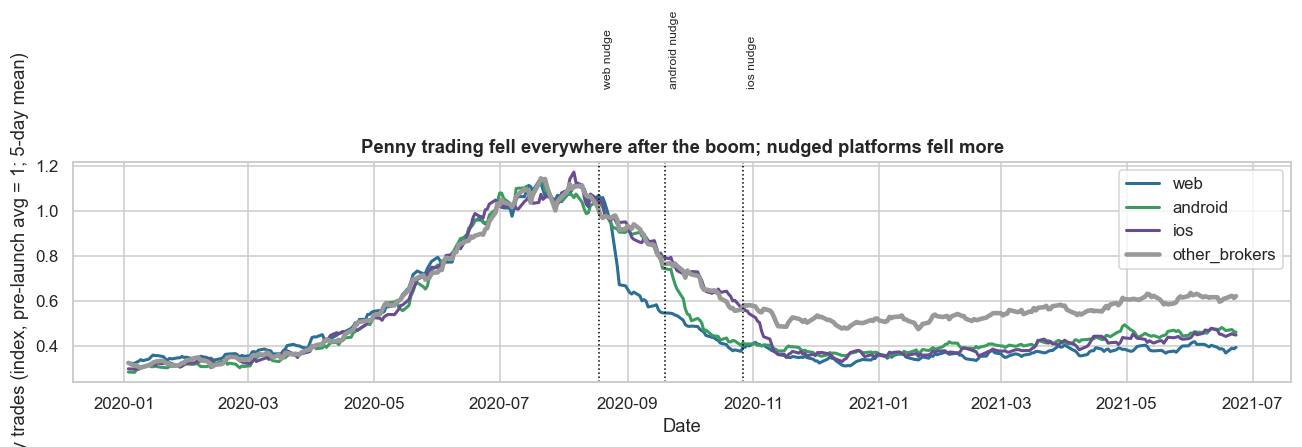

In [6]:
fig, ax = plt.subplots(figsize=(12, 4.8))
base = W[(W.index >= gen.START + pd.Timedelta(days=150)) & (W.index < gen.START + pd.Timedelta(days=220))].mean()
for p_, c_ in (("web", "#2a6f97"), ("android", "#3a9d5d"), ("ios", "#6a4c93"), ("other_brokers", "#999")):
    ax.plot(W.index, (W[p_] / base[p_]).rolling(5, min_periods=3).mean(), color=c_, lw=2 if p_ != "other_brokers" else 3, label=p_)
for p_, d_ in gen.LAUNCH.items(): ax.axvline(gen.START + pd.Timedelta(days=d_), color="black", ls=":", lw=1); ax.text(gen.START + pd.Timedelta(days=d_ + 2), 1.55, f"{p_} nudge", fontsize=8, rotation=90)
ax.set_xlabel("Date"); ax.set_ylabel("Penny trades (index, pre-launch avg = 1; 5-day mean)"); ax.set_title("Penny trading fell everywhere after the boom; nudged platforms fell more"); ax.legend()
plt.tight_layout(); plt.show()

**Takeaway:** indexed to their pre-launch average, **all four series rise into the 2020 boom and then fall**, including **other brokers, who never had a nudge** (grey). The nudged platforms fall *further*, and each one bends down at its own launch date (dotted lines): web first, then Android, then iOS. This picture is the whole argument: part of the decline is the market (shared by everyone), and part is the nudge (the extra drop at each platform's own launch). A before/after on one platform cannot separate the two.

## 7. Statistical Analysis (core section)

### 7.1 The documented method: before vs after

The broker's daily penny trades (all 3 platforms) in the **60 trading days before the first launch** vs **60 trading days starting 30 days after the last launch**. Test: a **Poisson rate ratio** on daily totals (with a quasi-Poisson correction for over-dispersion).

In [7]:
pre = broker[(broker.index >= gen.START + pd.Timedelta(days=140)) & (broker.index < gen.START + pd.Timedelta(days=230))].dropna().iloc[-60:]
post = broker[broker.index >= gen.START + pd.Timedelta(days=330)].dropna().iloc[:60]
rr = post.mean() / pre.mean(); phi = max(1, np.var(np.r_[pre / pre.mean(), post / post.mean()]) * np.mean(np.r_[pre, post]))
se = np.sqrt(phi * (1 / pre.sum() + 1 / post.sum()))
print(f"Pre: {pre.mean():,.0f} trades/day | post: {post.mean():,.0f} trades/day → change {rr - 1:+.1%} (95% CI {np.exp(np.log(rr) - 1.96 * se) - 1:+.1%} to {np.exp(np.log(rr) + 1.96 * se) - 1:+.1%}); dispersion φ = {phi:,.0f}")
ob = W.other_brokers; pre_o = ob.loc[pre.index].mean(); post_o = ob.loc[post.index].mean()
print(f"Other brokers (no nudge) over the same windows: {post_o / pre_o - 1:+.1%}")

Pre: 16,856 trades/day | post: 6,316 trades/day → change -62.5% (95% CI -64.1% to -60.9%); dispersion φ = 129
Other brokers (no nudge) over the same windows: -46.8%


**Observation:** the documented-style comparison shows daily penny trades falling from **16,856 to 6,316: −62.5%** (95% CI −64.1% to −60.9%, even allowing for heavy over-dispersion, φ ≈ 129). It looks precise and decisive. But **other brokers with no nudge fell −46.8% over exactly the same windows**: most of the drop is the market cooling after the speculative peak. The tight CI is no comfort. It measures noise, not bias. **(f) Business meaning:** this is how press-release impact numbers get inflated. The "more than 50%" may be true as a description, but it is not the nudge's effect.

### 7.2 Interrupted time series: does the trend break at launch?

**(a) Why?** ITS uses the pre-launch trend to predict what would have happened. **Segmented regression** on log daily broker trades (first launch = day 230):

log Y_t = β₀ + β₁·t + β₂·post_t + β₃·(t − 230)·post_t + weekday effects (+ γ·log market control)

**(b) Assumptions:** the pre-trend would have continued (fragile when the market turns), and no other change at launch. Errors are autocorrelated, so we use **Newey–West (HAC)** standard errors with 10 lags. We fit it (i) without and (ii) with other brokers' log trades as a market control.

In [8]:
its = pd.DataFrame({"ly": np.log(broker), "t": (broker.index - gen.START).days, "wd": broker.index.weekday, "lctrl": np.log(W.other_brokers)}).dropna()
its = its[(its.t >= 120) & (its.t < 400)]
its["post"] = (its.t >= 230).astype(int); its["tpost"] = np.maximum(its.t - 230, 0)
m1 = smf.ols("ly ~ t + post + tpost + C(wd)", data=its).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
m2 = smf.ols("ly ~ t + post + tpost + C(wd) + lctrl", data=its).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
def eff_at(m, k=60):
    c = m.params; V = m.cov_params(); g = np.zeros(len(c)); g[list(c.index).index("post")] = 1; g[list(c.index).index("tpost")] = k
    est = g @ c.values; s = np.sqrt(g @ V.values @ g); return est, s
rows = []
for nm, m in (("ITS, no control", m1), ("ITS + market control (other brokers)", m2)):
    e60, s60 = eff_at(m); rows.append((nm, m.params["post"], m.pvalues["post"], m.params["tpost"], m.pvalues["tpost"], np.exp(e60) - 1, np.exp(e60 - 1.96 * s60) - 1, np.exp(e60 + 1.96 * s60) - 1))
itst = pd.DataFrame(rows, columns=["model", "level change (log)", "p level", "slope change (log/day)", "p slope", "effect at day +60", "CI low", "CI high"]).set_index("model")
itst.round(4)

,level change (log),p level,slope change (log/day),p slope,effect at day +60,CI low,CI high
model,,,,,,,
"ITS, no control",-0.5500,0.0000,-0.0123,0.0000,-0.7237,-0.7927,-0.6318
ITS + market control (other brokers),-0.1272,0.0015,-0.0015,0.0456,-0.1975,-0.2982,-0.0823


**(c)/(f) Observation:** - **ITS on the broker's own series** estimates a level drop of −0.55 log points plus a steeper downward slope, an effect of **−72%** 60 days after launch. That is even worse than pre/post: the pre-launch trend was the *boom* (rising), so projecting it forward makes the counterfactual far too high.
- **Adding other brokers' trades as a market control** shrinks the estimate to **−20%** (CI −30% to −8%; level p = 0.002, slope p = 0.046), which is plausible but imprecise, and it still relies on one series.
- **(f) Business meaning:** ITS is only as good as its counterfactual trend. Through a market turn, a single-series ITS is unreliable; with a control series it becomes a reasonable cross-check.

### 7.3 Difference-in-differences with the staggered rollout

**(a) Why?** Other brokers' first-time investors face the same market but no nudge. Each nudged platform is compared with them: the change in the gap when its nudge goes live is the effect.

**Model** (log daily trades, platform-days stacked; each platform compared only with the never-treated control, avoiding the known bias of two-way fixed effects with staggered timing):

log Y_pt = α_p + δ_t + τ·nudge_live_pt + ε_pt

τ is the average effect, and exp(τ) − 1 is the % change. We use date fixed effects (which absorb the market cycle completely) and HAC/cluster-robust SEs by week.

**(b) Parallel trends:** an **event study** replaces τ with weekly coefficients relative to launch (−8 to +12 weeks; week −1 as reference). The pre-launch coefficients should be ≈ 0, which we test jointly with a Wald test.

In [9]:
panel = d0[["date", "t", "week", "platform", "ly", "nudge_live"]].dropna().copy()
panel = panel[(panel.t >= 120) & (panel.t < 420)]
res = []
for p_ in ["web", "android", "ios"]:
    sub = panel[panel.platform.isin([p_, "other_brokers"])].copy()
    m = smf.ols("ly ~ C(platform) + C(date) + nudge_live", data=sub).fit(cov_type="cluster", cov_kwds={"groups": sub.week})
    res.append((p_, gen.LAUNCH[p_], m.params["nudge_live"], m.bse["nudge_live"], np.exp(m.params["nudge_live"]) - 1,
                np.exp(m.params["nudge_live"] - 1.96 * m.bse["nudge_live"]) - 1, np.exp(m.params["nudge_live"] + 1.96 * m.bse["nudge_live"]) - 1, m.pvalues["nudge_live"]))
did = pd.DataFrame(res, columns=["platform", "launch day", "τ (log)", "SE", "% change", "CI low", "CI high", "p"]).set_index("platform")
rob = {}
for p_ in ["web", "android", "ios"]:                                                    # robustness: allow each platform its own linear trend vs control
    sub = panel[panel.platform.isin([p_, "other_brokers"])].copy(); sub["trt_t"] = (sub.platform == p_) * (sub.t - 230) / 100
    m = smf.ols("ly ~ C(platform) + C(date) + trt_t + nudge_live", data=sub).fit(cov_type="cluster", cov_kwds={"groups": sub.week}); rob[p_] = np.exp(m.params["nudge_live"]) - 1
did["% change with platform trend"] = pd.Series(rob)
w_ = 1 / did.SE ** 2; tau_pool = (w_ * did["τ (log)"]).sum() / w_.sum(); se_pool = np.sqrt(1 / w_.sum())
Q = (w_ * (did["τ (log)"] - tau_pool) ** 2).sum()
print(f"Pooled DiD (inverse-variance across platforms): {np.exp(tau_pool) - 1:+.1%} (95% CI {np.exp(tau_pool - 1.96 * se_pool) - 1:+.1%} to {np.exp(tau_pool + 1.96 * se_pool) - 1:+.1%}); "
      f"heterogeneity Q = {Q:.2f} (p = {stats.chi2.sf(Q, 2):.2f}) | truth: −30%")
did.round(4)

Pooled DiD (inverse-variance across platforms): -28.3% (95% CI -30.0% to -26.5%); heterogeneity Q = 7.63 (p = 0.02) | truth: −30%


,launch day,τ (log),SE,% change,CI low,CI high,p,% change with platform trend
platform,,,,,,,,
web,230,-0.3766,0.0208,-0.3138,-0.3412,-0.2852,0.0000,-0.2608
android,262,-0.2981,0.0200,-0.2577,-0.2863,-0.2280,0.0000,-0.2548
ios,300,-0.3213,0.0256,-0.2748,-0.3103,-0.2375,0.0000,-0.2725


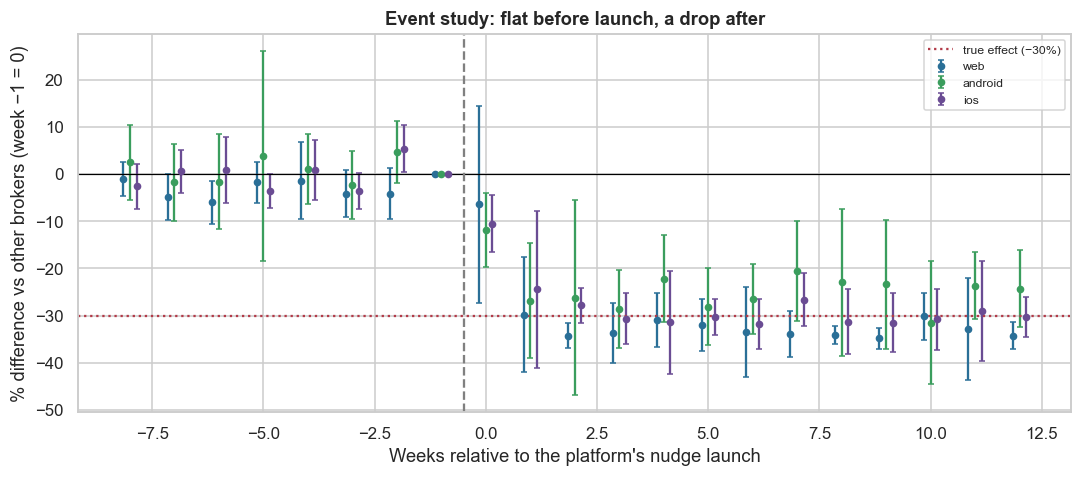

,joint test of 7 pre-launch weeks = 0 (p),largest |pre-launch weekly deviation| (%),"average post-launch effect, weeks +2..+12 (%)"
platform,,,
android,0.0000,4.6175,-25.3349
ios,0.0000,5.3538,-30.1685
web,0.0911,6.4069,-33.1399


In [10]:
ev = []
for p_ in ["web", "android", "ios"]:
    sub = panel[panel.platform.isin([p_, "other_brokers"])].copy(); rel = (sub.t - gen.LAUNCH[p_]) // 7
    sub["rel"] = np.where(sub.platform == p_, rel.clip(-8, 12), -99)
    for k in range(-8, 13):
        if k == -1: continue
        sub[f"e{k + 8}"] = (sub.rel == k).astype(int)
    terms = " + ".join(f"e{k + 8}" for k in range(-8, 13) if k != -1)
    m = smf.ols(f"ly ~ C(platform) + C(date) + {terms}", data=sub).fit(cov_type="cluster", cov_kwds={"groups": sub.week})
    pre_terms = [f"e{k + 8}" for k in range(-8, -1)]; wald = m.wald_test(" , ".join(f"{t_} = 0" for t_ in pre_terms), scalar=True)
    for k in range(-8, 13):
        if k == -1: ev.append((p_, k, 0.0, 0.0, wald.pvalue)); continue
        ev.append((p_, k, m.params[f"e{k + 8}"], m.bse[f"e{k + 8}"], wald.pvalue))
ev = pd.DataFrame(ev, columns=["platform", "week rel. to launch", "coef", "se", "pre-trend Wald p"])
fig, ax = plt.subplots(figsize=(10, 4.5))
for p_, c_, off in (("web", "#2a6f97", -0.15), ("android", "#3a9d5d", 0), ("ios", "#6a4c93", 0.15)):
    e_ = ev[ev.platform == p_]; ax.errorbar(e_["week rel. to launch"] + off, (np.exp(e_.coef) - 1) * 100, yerr=1.96 * e_.se * 100, fmt="o", ms=4, capsize=2, color=c_, label=p_)
ax.axhline(0, color="black", lw=0.8); ax.axvline(-0.5, color="grey", ls="--"); ax.axhline(-30, color="#b23a48", ls=":", label="true effect (−30%)")
ax.set_xlabel("Weeks relative to the platform's nudge launch"); ax.set_ylabel("% difference vs other brokers (week −1 = 0)"); ax.set_title("Event study: flat before launch, a drop after"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
pre_ev = ev[(ev["week rel. to launch"] < -1)]
pd.DataFrame({"joint test of 7 pre-launch weeks = 0 (p)": ev.groupby("platform")["pre-trend Wald p"].first(),
              "largest |pre-launch weekly deviation| (%)": pre_ev.groupby("platform").coef.apply(lambda c: (np.exp(c.abs().max()) - 1) * 100),
              "average post-launch effect, weeks +2..+12 (%)": ev[ev["week rel. to launch"] >= 2].groupby("platform").coef.apply(lambda c: (np.exp(c.mean()) - 1) * 100)}).round(4)

**Takeaway:** - **Each platform vs other brokers** (date fixed effects absorb the market cycle completely):
  - **Web −31.4%** (CI −34.1% to −28.5%).
  - **Android −25.8%**.
  - **iOS −27.5%**.
  - Pooled **−28.3%** (CI −30.0% to −26.5%). That is close to the true −30%, recovered three separate times at three different launch dates, which is hard to explain by anything other than the nudge. The platforms differ somewhat (Q = 7.6, p = 0.02).
- **Event study (chart):** the weekly coefficients are near zero before each launch, then fall to about −25% to −33% within two weeks.
- **The formal pre-trend tests reject for Android and iOS** (p < 0.001; web p = 0.09). The pre-launch wobbles are small (at most 4.6–6.4%), but with ~1,500–9,000 trades a day the test can detect even tiny drifts.
- **Robustness:** allowing each platform its own linear trend gives **−25% to −27%**, the same conclusion.
- **(f) Business meaning:** the staggered rollout plus a never-nudged comparison group turns an anecdote into evidence. Parallel trends are never perfect, so always show the size of pre-launch deviations next to the p-value.

### 7.4 Placebo tests: would the method "find" an effect where none exists?

We re-run the DiD with **fake launch dates** in the pre-period (days 140, 170 and 200, all before any real nudge, using only pre-launch data). A credible method should find ≈ 0. We also run the same **naive pre/post** on the *control* (other brokers), which never had a nudge.

In [11]:
pl = []
for fake in (140, 170, 200):
    for p_ in ["web", "android", "ios"]:
        sub = panel[panel.platform.isin([p_, "other_brokers"]) & (panel.t < min(gen.LAUNCH.values()))].copy()
        sub["fake"] = ((sub.platform == p_) & (sub.t >= fake)).astype(int)
        m = smf.ols("ly ~ C(platform) + C(date) + fake", data=sub).fit(cov_type="cluster", cov_kwds={"groups": sub.week})
        pl.append((fake, p_, np.exp(m.params["fake"]) - 1, m.pvalues["fake"]))
pl = pd.DataFrame(pl, columns=["fake launch day", "platform", "placebo % change", "p"])
print(f"Naive pre/post on OTHER BROKERS (no nudge ever): {post_o / pre_o - 1:+.1%}, i.e., the market alone")
pl.round(4)

Naive pre/post on OTHER BROKERS (no nudge ever): -46.8%, i.e., the market alone


,fake launch day,platform,placebo % change,p
0,140,web,0.0240,0.3348
1,140,android,0.0390,0.3893
2,140,ios,0.0975,0.0000
3,170,web,-0.0180,0.4078
4,170,android,0.0091,0.7784
5,170,ios,0.0101,0.7633
6,200,web,-0.0121,0.6771
7,200,android,-0.0237,0.4878
8,200,ios,0.0101,0.7101


**Observation:** with fake launch dates (days 140/170/200, before any real nudge), the DiD finds **≈ 0 in 8 of 9 tests** (−2% to +4%, p ≥ 0.33). One placebo, iOS at day 140, shows **+9.8%** (p < 0.001). It has only four pre-weeks of data and sits in the noisiest, smallest series. One false alarm in nine at 5% is not alarming, but it is a reminder that short pre-periods make DiD fragile. By contrast, **naive pre/post on the never-nudged control "finds" −46.8%**: the method itself generates a large fake effect. **Business meaning:** the DiD passes its placebo checks; pre/post fails them badly.

### 7.5 The gold standard: a randomised holdout of users

**(a)** In the 90 days after full rollout, 5% of first-time investors are randomly kept in a **holdout** that never sees nudges. The share who trade penny stocks, compared between nudged and holdout users, is a pure causal estimate (ITT): no market confounding, no trend assumptions. Two-proportion z-test with a Newcombe CI; relative effect with a log-RR CI; balance check on age and capital.

In [12]:
h, n_ = users[users.holdout_no_nudge == 1], users[users.holdout_no_nudge == 0]
x1, N1, x0, N0 = n_.traded_penny_90d.sum(), len(n_), h.traded_penny_90d.sum(), len(h)
lo, hi = confint_proportions_2indep(x1, N1, x0, N0, method="newcomb"); z, p = proportions_ztest([x1, x0], [N1, N0])
rr_h = (x1 / N1) / (x0 / N0); se_h = np.sqrt(1 / x1 - 1 / N1 + 1 / x0 - 1 / N0)
smd_age = (n_.age.mean() - h.age.mean()) / np.sqrt((n_.age.var() + h.age.var()) / 2)
print(f"Holdout n = {N0:,} ({N0 / len(users):.1%}) | balance SMD(age) = {smd_age:.3f}")
print(f"Traded penny stocks in 90 days: nudged {x1 / N1:.2%} vs holdout {x0 / N0:.2%} → {(x1 / N1 - x0 / N0) * 100:+.2f} pp (CI {lo * 100:+.2f} to {hi * 100:+.2f}), z = {z:.1f}, p = {p:.2g}")
print(f"Relative effect: {rr_h - 1:+.1%} (95% CI {np.exp(np.log(rr_h) - 1.96 * se_h) - 1:+.1%} to {np.exp(np.log(rr_h) + 1.96 * se_h) - 1:+.1%}) | truth −30%")
loss_d = n_.penny_loss_90d_inr.mean() - h.penny_loss_90d_inr.mean()
bsl = [users.iloc[i].groupby("holdout_no_nudge").penny_loss_90d_inr.mean().pipe(lambda s: s[0] - s[1]) for i in (RNG.integers(0, len(users), len(users)) for _ in range(500))]
print(f"Penny-stock losses per user in 90 days: nudged ₹{n_.penny_loss_90d_inr.mean():,.0f} vs holdout ₹{h.penny_loss_90d_inr.mean():,.0f} → ₹{loss_d:,.0f} per user (CI ₹{np.percentile(bsl, 2.5):,.0f} to ₹{np.percentile(bsl, 97.5):,.0f})")

Holdout n = 6,011 (5.0%) | balance SMD(age) = 0.003
Traded penny stocks in 90 days: nudged 15.98% vs holdout 23.47% → -7.49 pp (CI -8.60 to -6.42), z = -15.3, p = 6.7e-53
Relative effect: -31.9% (95% CI -35.1% to -28.6%) | truth −30%


Penny-stock losses per user in 90 days: nudged ₹576 vs holdout ₹856 → ₹-280 per user (CI ₹-350 to ₹-211)


**(c)/(f) Observation:** - **The holdout is balanced** (6,011 users, 5.0%; age SMD 0.003).
- **Users who never saw nudges** traded penny stocks **23.5%** of the time in 90 days, vs **16.0%** for nudged users: **−7.5 pp** (CI −8.6 to −6.4; z = −15.3, p ≈ 1e-53), a relative effect of **−31.9%** (CI −35.1% to −28.6%). This matches the true −30% and the DiD.
- **Realised penny-stock losses** are **₹280 lower per user per quarter** (₹576 vs ₹856; CI ₹211–350).
- **(f) Business meaning:** this is the cleanest evidence, with no market assumptions at all. It also directly measures the investor-protection value in ₹.

### 7.6 How big must the holdout be?

A holdout costs something: those users miss the protection. Below: the minimum detectable relative reduction (80% power, α = 0.05) for different holdout shares of 1.2 lakh users, base rate 23%.

In [13]:
p_h = x0 / N0; rows = []
for share in (0.01, 0.02, 0.05, 0.10):
    nh, nn = 120000 * share, 120000 * (1 - share); se_ = np.sqrt(p_h * (1 - p_h) * (1 / nh + 1 / nn)); mde = (1.96 + 0.84) * se_ / p_h
    rows.append((f"{share:.0%}", int(nh), mde))
pd.DataFrame(rows, columns=["holdout share", "holdout users", "minimum detectable relative reduction"]).set_index("holdout share").round(4)

,holdout users,minimum detectable relative reduction
holdout share,,
1%,1200,0.1467
2%,2400,0.1042
5%,6000,0.0670
10%,12000,0.0486


**Observation:** with 1.2 lakh users and a 23% base rate, a **2% holdout** (2,400 users) detects a ~10% relative reduction, and a **5% holdout** (6,000 users) detects ~7%. **Business meaning:** a very small holdout is enough to prove an effect of this size (~30%). Keeping it at 2% for a quarter minimises the number of investors who go without the warning, which addresses the ethical concern.

## 8. ML Section — deliberately none

The documented intervention is **rule-based** ("Rules flag risky instruments"), and Zerodha says it deliberately avoids behavioural tracking. We agree that no ML is needed to *run* the nudge. The data-science work is entirely in **measuring** it, which is where this notebook spends its effort. That is the reference file's lesson: "Not every intervention needs ML. Sometimes the analysis *is* the decision."

## 9. Business Translation — "probably saving tens of crores": how much, really?

Assumptions (D-29-07):
- Penny-trade volume and losses are scaled to a broker with 20 lakh active first-time investors.
- The average loss per penny trade comes from the holdout study.

We compute penny trades avoided per year under each estimate of the effect.

In [14]:
avg_loss = h.loc[h.traded_penny_90d == 1, "penny_loss_90d_inr"].mean(); BASE_TRADERS = 2e6
p_base = x0 / N0
ests = {"naive pre/post (documented style)": rr - 1, "ITS + market control": itst.iloc[1]["effect at day +60"], "DiD (pooled, vs other brokers)": np.exp(tau_pool) - 1, "randomised holdout": rr_h - 1}
proj = pd.DataFrame([(k, v, BASE_TRADERS * p_base * (-v) * 4, BASE_TRADERS * p_base * (-v) * 4 * avg_loss / 1e7) for k, v in ests.items()],
                    columns=["estimate", "% change in penny trading", "first-time investors protected / year", "losses avoided ₹ crore / year"]).set_index("estimate")
print(f"Average 90-day loss of a holdout user who traded penny stocks ≈ ₹{avg_loss:,.0f}")
proj.round(3)

Average 90-day loss of a holdout user who traded penny stocks ≈ ₹3,645


,% change in penny trading,first-time investors protected / year,losses avoided ₹ crore / year
estimate,,,
naive pre/post (documented style),-0.6250,"1,174,216.1240",428.0540
ITS + market control,-0.1970,"370,820.2590",135.1810
"DiD (pooled, vs other brokers)",-0.2830,"530,943.0350",193.5520
randomised holdout,-0.3190,"599,451.3860",218.5270


**Takeaway (business reading):** for a broker with **20 lakh active first-time investors** (≈ ₹3,645 average 90-day loss per penny trader, from the holdout):

| Estimate | Investors protected a year | Losses avoided |
|---|---|---|
| **Holdout (best estimate)** | ≈ **6.0 lakh** | ≈ **₹219 crore/year** |
| DiD | ≈ 5.3 lakh | ≈ ₹194 crore/year |
| ITS + control | — | ≈ ₹135 crore/year |
| Naive pre/post | — | ≈ ₹428 crore/year, about **2× overstated** |

- **Reading:** the nudge is valuable on any credible estimate (the documented "tens of crores" is, if anything, an *under*statement at this scale). The point of better methods is not to shrink the good news but to report a number that survives scrutiny by a regulator or a sceptical board.
- Losses avoided are investors' money, not broker revenue. Brokers may even lose some brokerage, which makes the decision an investor-protection choice.

## 10. Recommendation and Decision

**Decision against the hypotheses:**
- **H1** rejected: pre/post shows a drop, but it is biased (control −47%).
- **H2:** ITS shows a break only with a market control (−20%).
- **H3 ✅:** DiD −28% (CI −30% to −27%), consistent across three staggered launches and robust to platform trends.
- **H4 ✅:** holdout −32% (p ≈ 1e-53).
- **Conclusion:** the nudge causes a **≈ 30% reduction** in penny-stock trading by first-time investors, not "more than 50%".

**I recommend:**
1. **Keep and extend the nudge** (to F&O for first-time investors, illiquid SME stocks, etc.). It is a cheap, rule-based, highly effective protection.
2. **Measure every such launch credibly:**
   - Roll out in **stages** (by platform, city or user cohort).
   - Benchmark against a **never-treated** group (other brokers' public data, or untreated segments).
   - Keep a **2% randomised holdout** for one quarter.
3. **Report impact as "−30% (holdout), −28% (DiD)",** not a pre/post figure, especially through market turns.
4. **Check displacement:** track total risky activity per user (penny + F&O + other brokers where visible), not just the nudged product.
5. **Automate data hygiene:** treat missing exchange files as missing, never as zero.

**KPIs:** holdout-controlled % reduction in penny trades per first-time investor; DiD estimate per rollout wave; realised losses per user (nudged vs holdout); share of first-time investors who proceed after seeing a nudge; displacement to other risky products.

## 11. Risks, Limitations and Next Steps

- **Synthetic market and effect:** the market cycle and the −30% effect were assumed to show how methods differ. Real numbers would differ, but the ranking of methods by credibility would not.
- **Control-group validity:** other brokers' first-time investors may differ (different marketing, different apps). The event-study pre-trends (7.3) and placebos (7.4) are the checks, and they must be re-run on real data.
- **Displacement:** nudged users might move penny trading to another broker or to other risky products (F&O). Measure total risky trading per user, not just penny trades on one platform.
- **Ethics of holdouts:** withholding a protective warning from a few percent of users is a real cost. Keep the holdout small (2–5%), time-limited, and approved by compliance. Alternatively, use the staggered rollout itself as the experiment.
- **Regulatory context:** SEBI's later F&O risk disclosures (2023–24) are a similar intervention, and the same DiD/event-study toolkit applies to measuring them.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Pre/post rate ratio | RR = mean(post)/mean(pre); quasi-Poisson SE √(φ(1/Σpre + 1/Σpost)) |
| Segmented ITS | log Y = β₀ + β₁t + β₂·post + β₃·(t − t₀)·post + seasonality |
| Newey–West | HAC covariance robust to autocorrelation (lag L = 10) |
| DiD (log-linear) | log Y_pt = α_p + δ_t + τ·D_pt; % effect = e^τ − 1 |
| Event study | log Y_pt = α_p + δ_t + Σ_k β_k·1{t − t₀,p ∈ week k} (k = −1 reference) |
| Holdout ITT | p_nudged − p_holdout; RR CI via log RR |
| MDE | (z₀.₉₇₅ + z₀.₈)·√(p(1 − p)(1/n_h + 1/n_t)) / p |

| Term | Meaning |
|---|---|
| Nudge | A warning or prompt that steers a choice without forbidding it |
| Penny stock | A very low-priced, often illiquid, highly speculative share |
| Confounder | Something else changing at the same time (here, the market cycle) |
| Interrupted time series | Testing for a break in a series' trend at an intervention |
| Difference-in-differences | Comparing the change in a treated group with the change in a control group |
| Staggered rollout | Launching to different groups at different times |
| Holdout | A random group kept without the intervention to measure its effect |
| Placebo test | Applying the method where no effect should exist |